# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

**Discuss with your partner, and make notes here.**

2. Explain what "recall" represents in this context.

**Discuss with your partner, and make notes here.**

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

**Discuss with your partner, and make notes here.**

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

**Discuss with your partner, and make notes here.**

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

**Discuss with your partner, and make notes here.**

6. What is a downside to your choice in the previous part?

**Discuss with your partner, and make notes here.**

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [2]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


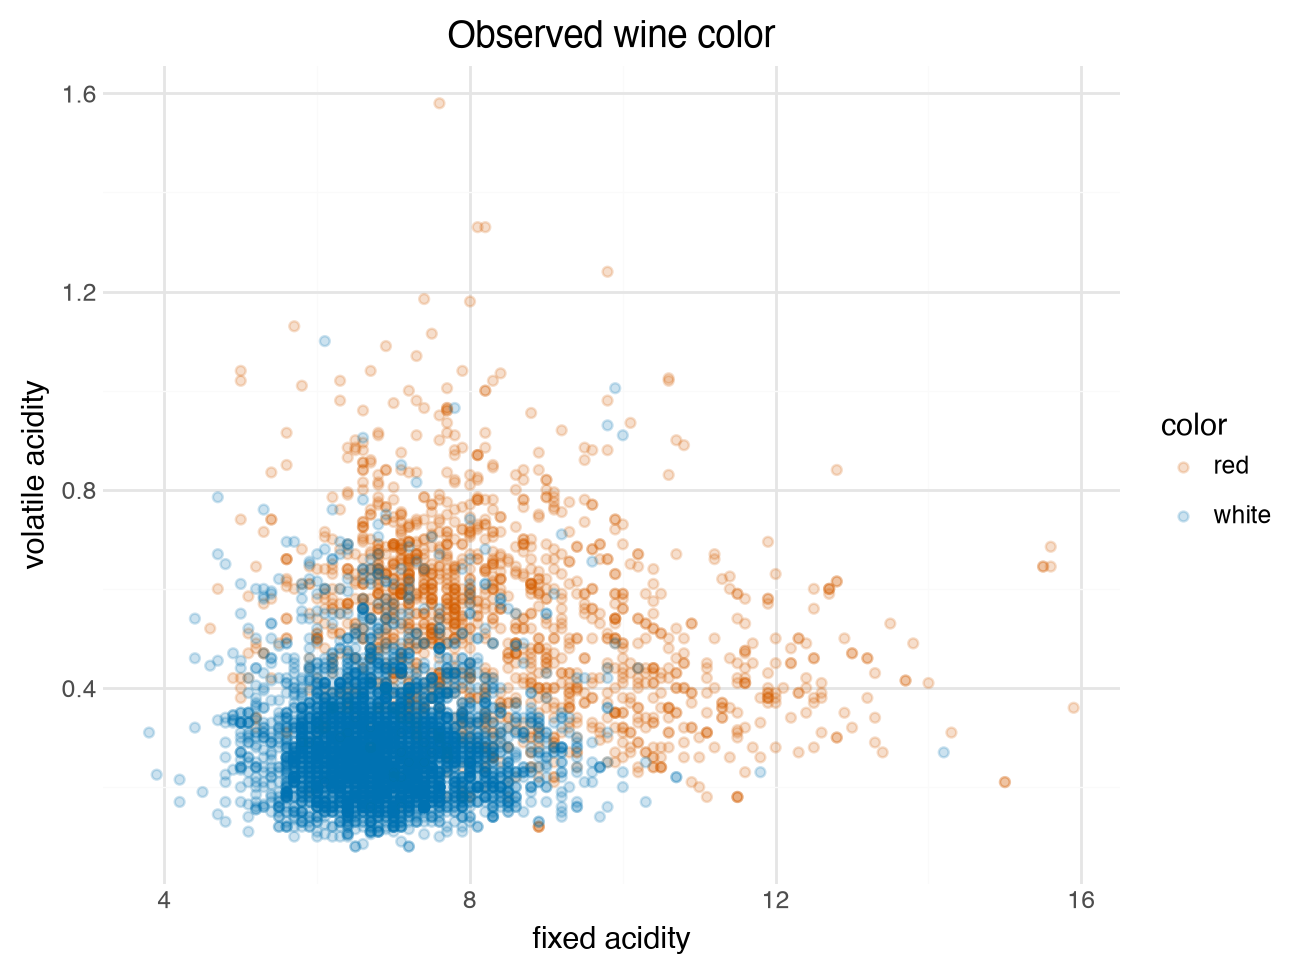

In [3]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

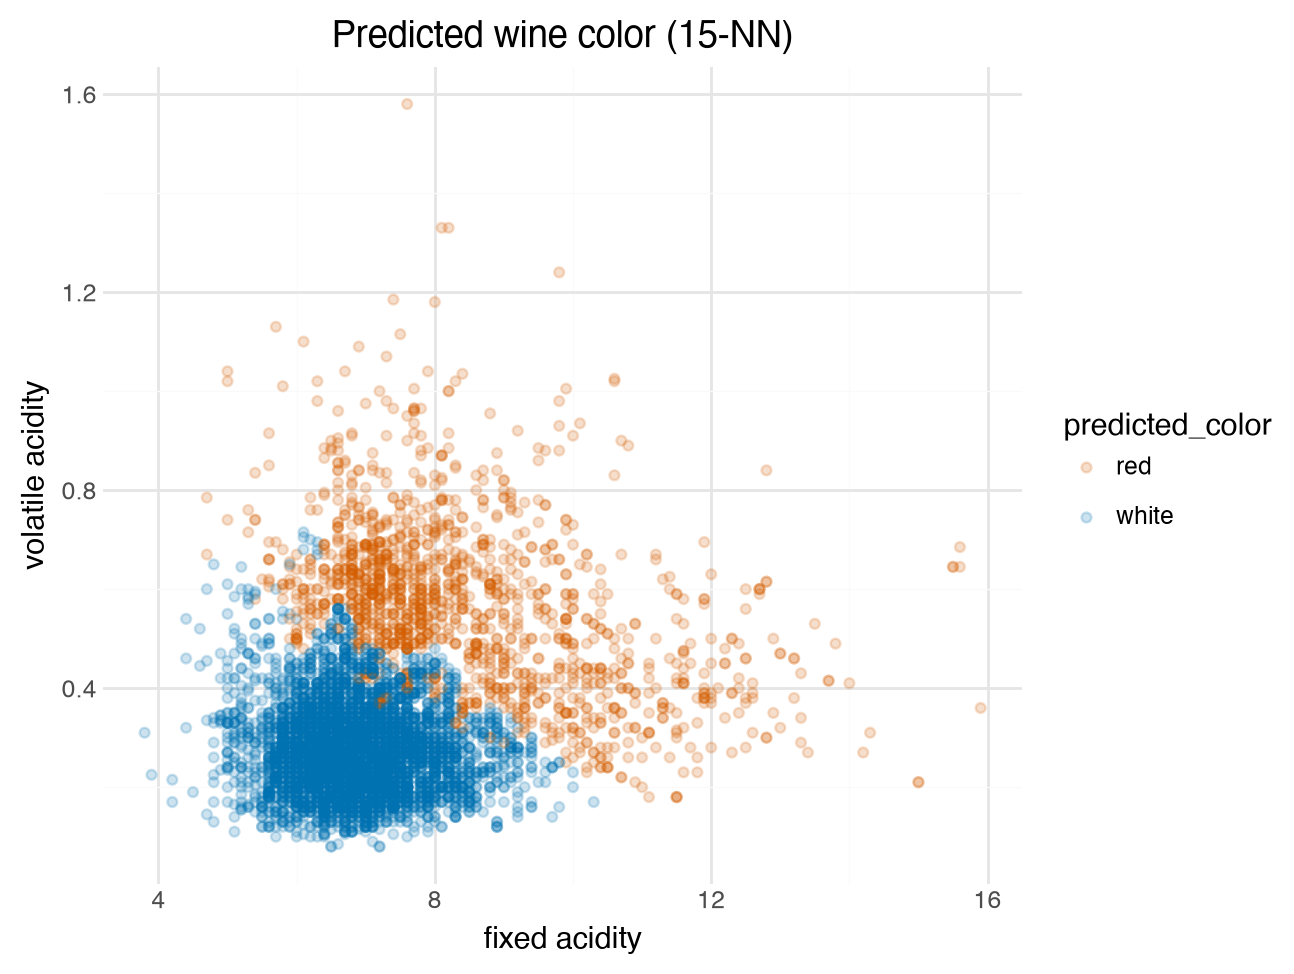

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from plotnine import *

X = df_train[["fixed acidity", "volatile acidity"]]
y = df_train["color"]

pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)
pipeline.fit(X, y)


df_train = df_train.copy()
df_train["predicted_color"] = pipeline.predict(X)


plot = (
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="predicted_color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (15-NN)", color="predicted_color")
    + theme_minimal()
)
plot

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [5]:
from sklearn.model_selection import cross_validate

scoring = ['precision_macro', 'recall_macro', 'f1_macro']

scores = cross_validate(pipeline, X, y, cv=10, scoring=scoring)

print(f"Estimated Test Precision (Macro): {scores['test_precision_macro'].mean():.4f}")
print(f"Estimated Test Recall (Macro):    {scores['test_recall_macro'].mean():.4f}")
print(f"Estimated Test F1 Score (Macro):  {scores['test_f1_macro'].mean():.4f}")

Estimated Test Precision (Macro): 0.8814
Estimated Test Recall (Macro):    0.8544
Estimated Test F1 Score (Macro):  0.8633


3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

Best k: 16
Best macro F1 score: 0.8664


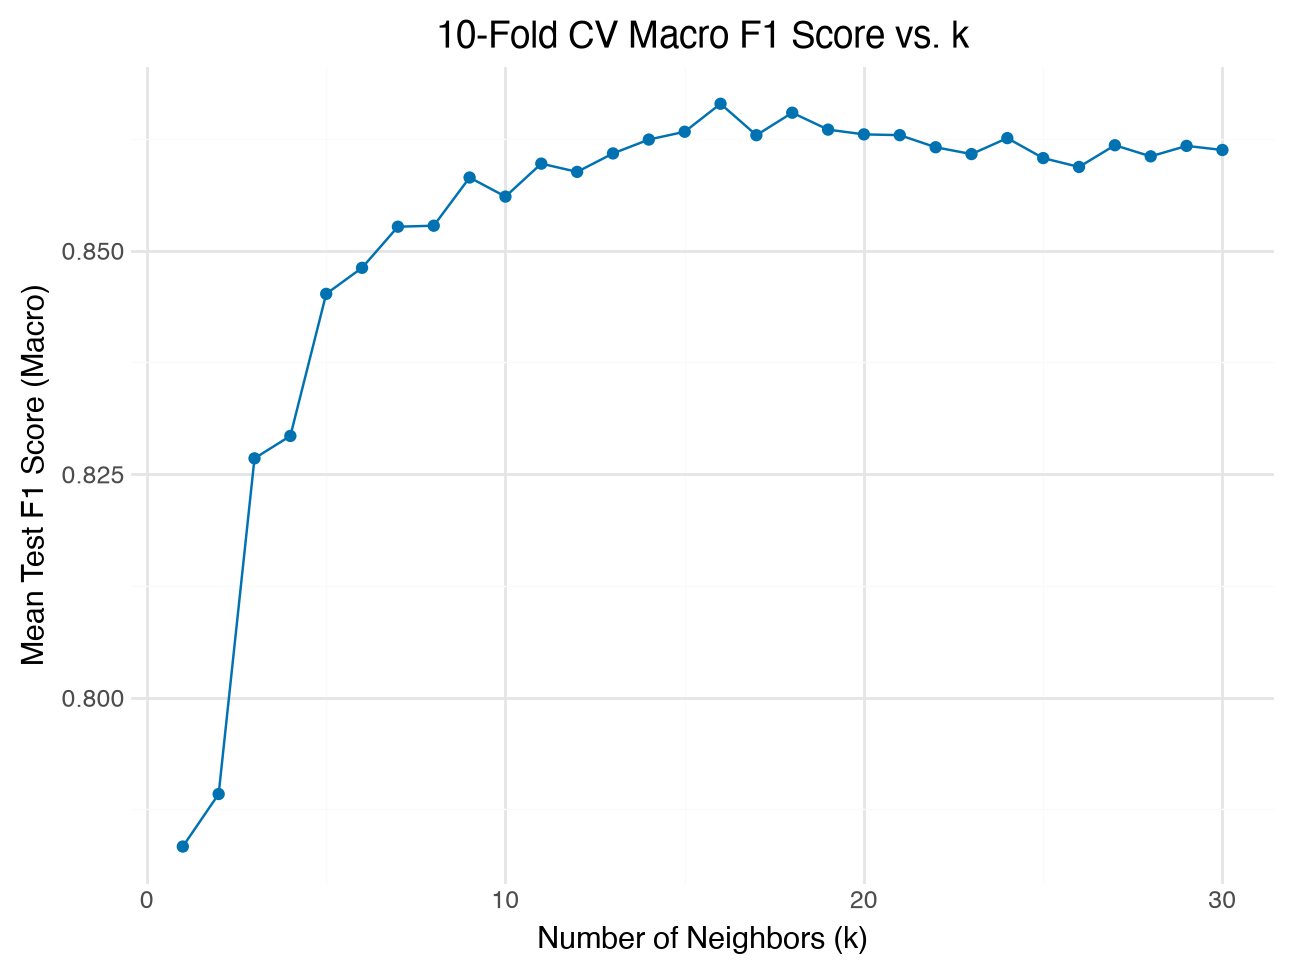

In [6]:
import pandas as pd
from sklearn.model_selection import GridSearchCV

# 1. Set up grid search parameters (k from 1 to 30)
param_grid = {"kneighborsclassifier__n_neighbors": range(1, 31)}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=10,
    scoring="f1_macro",
    return_train_score=False
)
grid_search.fit(X, y)

cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results["k"] = range(1, 31)


plot_cv = (
    ggplot(cv_results, aes(x="k", y="mean_test_score"))
    + geom_line(color="#0072B2")
    + geom_point(color="#0072B2")
    + labs(
        title="10-Fold CV Macro F1 Score vs. k",
        x="Number of Neighbors (k)",
        y="Mean Test F1 Score (Macro)"
    )
    + theme_minimal()
)
print(f"Best k: {grid_search.best_params_['kneighborsclassifier__n_neighbors']}")
print(f"Best macro F1 score: {grid_search.best_score_:.4f}")
plot_cv

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

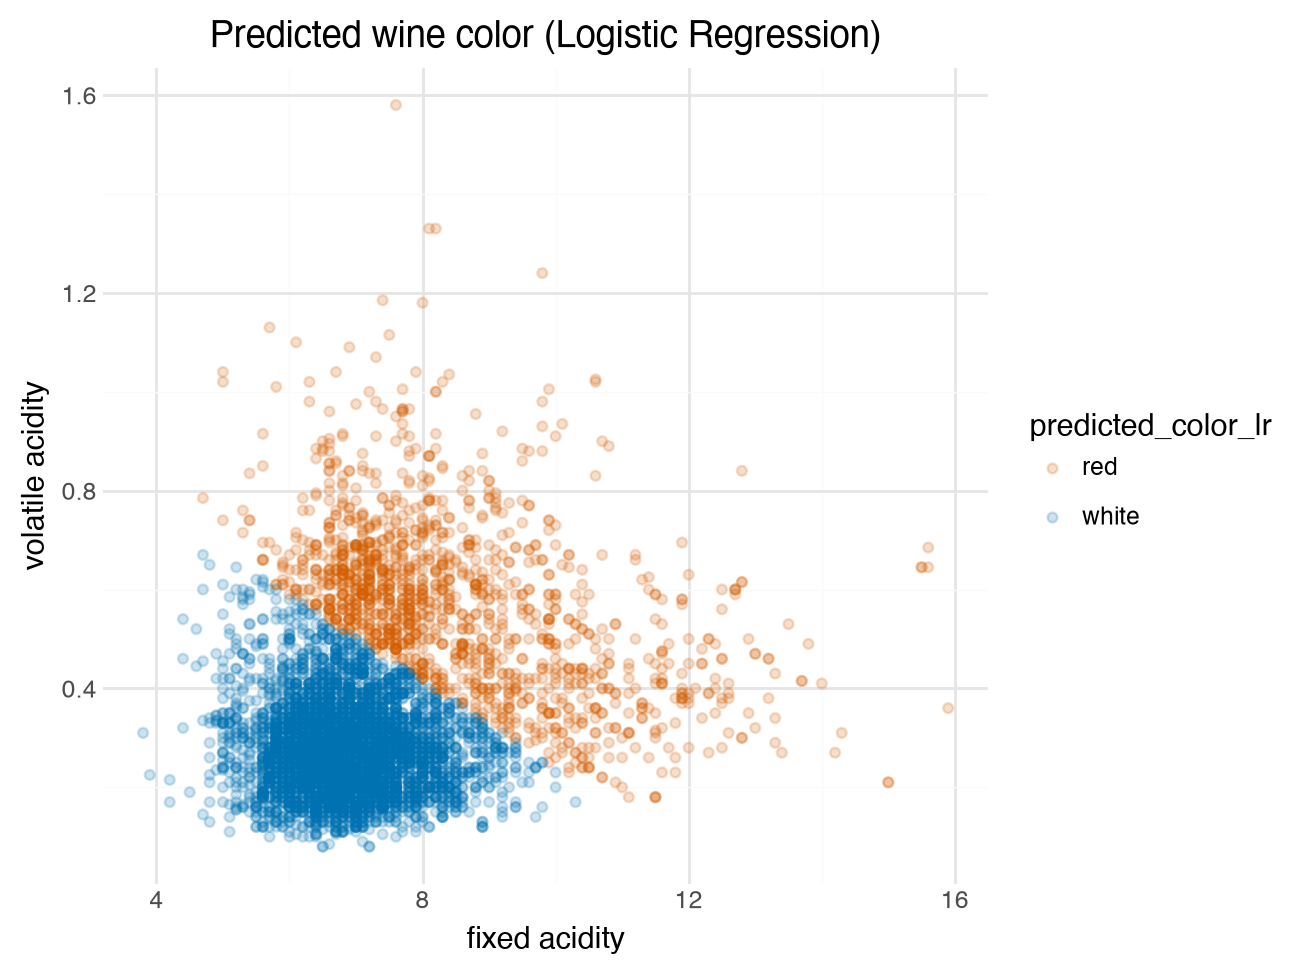

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from plotnine import *


X = df_train[["fixed acidity", "volatile acidity"]]
y = df_train["color"]

log_reg_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)
log_reg_pipeline.fit(X, y)

df_train = df_train.copy()
df_train["predicted_color_lr"] = log_reg_pipeline.predict(X)

# plot
plot_lr = (
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="predicted_color_lr"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (Logistic Regression)", color="predicted_color_lr")
    + theme_minimal()
)
plot_lr

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [8]:
from sklearn.model_selection import cross_validate
scoring = ['precision_macro', 'recall_macro', 'f1_macro']
lr_scores = cross_validate(log_reg_pipeline, X, y, cv=10, scoring=scoring)
print("=== Logistic Regression (10-Fold CV) ===")
print(f"Estimated Test Precision (Macro): {lr_scores['test_precision_macro'].mean():.4f}")
print(f"Estimated Test Recall (Macro):    {lr_scores['test_recall_macro'].mean():.4f}")
print(f"Estimated Test F1 Score (Macro):  {lr_scores['test_f1_macro'].mean():.4f}")

=== Logistic Regression (10-Fold CV) ===
Estimated Test Precision (Macro): 0.8916
Estimated Test Recall (Macro):    0.8519
Estimated Test F1 Score (Macro):  0.8643


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [9]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Define predictors (all columns except 'color') and the target variable
X_all = df_train.drop(columns=["color", "predicted_color", "predicted_color_lr"], errors="ignore")
y_all = df_train["color"]

# 2. Build the pipeline with scaling and Logistic Regression
full_lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# 3. Define the evaluation metrics
scoring = ['precision_macro', 'recall_macro', 'f1_macro']

# 4. Perform 10-fold cross-validation
full_lr_scores = cross_validate(full_lr_pipeline, X_all, y_all, cv=10, scoring=scoring)

# 5. Output the mean scores
print("=== Logistic Regression with All Predictors (10-Fold CV) ===")
print(f"Estimated Test Precision (Macro): {full_lr_scores['test_precision_macro'].mean():.4f}")
print(f"Estimated Test Recall (Macro):    {full_lr_scores['test_recall_macro'].mean():.4f}")
print(f"Estimated Test F1 Score (Macro):  {full_lr_scores['test_f1_macro'].mean():.4f}")

=== Logistic Regression with All Predictors (10-Fold CV) ===
Estimated Test Precision (Macro): 0.9918
Estimated Test Recall (Macro):    0.9903
Estimated Test F1 Score (Macro):  0.9911


7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [10]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_all = df_train.drop(columns=["color", "predicted_color", "predicted_color_lr"], errors="ignore")
y_all = df_train["color"]
lasso_lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=42)
)
scoring = ['precision_macro', 'recall_macro', 'f1_macro']

lasso_lr_scores = cross_validate(lasso_lr_pipeline, X_all, y_all, cv=10, scoring=scoring)

print("=== LASSO (L1) Logistic Regression with All Predictors (10-Fold CV) ===")
print(f"Estimated Test Precision (Macro): {lasso_lr_scores['test_precision_macro'].mean():.4f}")
print(f"Estimated Test Recall (Macro):    {lasso_lr_scores['test_recall_macro'].mean():.4f}")
print(f"Estimated Test F1 Score (Macro):  {lasso_lr_scores['test_f1_macro'].mean():.4f}")

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_rat

=== LASSO (L1) Logistic Regression with All Predictors (10-Fold CV) ===
Estimated Test Precision (Macro): 0.9920
Estimated Test Recall (Macro):    0.9901
Estimated Test F1 Score (Macro):  0.9911
